<a href="https://colab.research.google.com/github/juhisakshisurin/ITA0520-Computer-Vision/blob/main/Exp_25_Image_Classification_Using_MobileNetV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving -473Wx593H-469457011-black-MODEL.avif to -473Wx593H-469457011-black-MODEL.avif
Image uploaded successfully: -473Wx593H-469457011-black-MODEL.avif


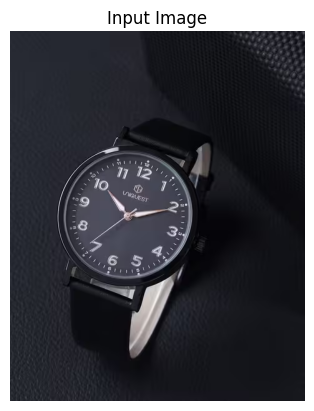

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
analog_clock : 41.73 %
stopwatch : 35.5 %
digital_watch : 1.58 %
wall_clock : 1.43 %
reel : 1.34 %


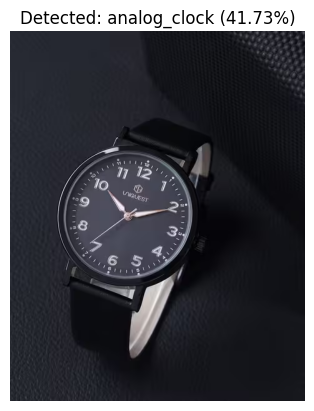

In [1]:

from google.colab import files
uploaded = files.upload()

import cv2
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input, decode_predictions
)

filename = list(uploaded.keys())[0]
image = cv2.imread(filename)

print("Image uploaded successfully:", filename)

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Input Image")
plt.axis("off")
plt.show()

model = MobileNetV2(weights="imagenet")

img = cv2.resize(image, (224, 224))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = np.expand_dims(img, axis=0)
img = preprocess_input(img)

predictions = model.predict(img)
results = decode_predictions(predictions, top=5)[0]

for _, label, confidence in results:
    print(label, ":", round(confidence * 100, 2), "%")

best_label = results[0][1]
confidence = results[0][2] * 100

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(f"Detected: {best_label} ({confidence:.2f}%)")
plt.axis("off")
plt.show()
